In [28]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import time
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None) # Show all columns
pd.set_option('display.width', 1000) # Adjust display width

In [29]:
df = pd.read_csv('CIC-IoT-IDAD-Dataset-2024-balanced_dataset.csv')

In [30]:
df.head()

,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Attack_type,Attack
0,6,291959,5,4,196.0,375.0,196.0,0.0,39.2,87.653865,375.0,0.0,93.75,187.5,1955.754061,30.826246,36494.875,57448.362362,147841.0,1.0,274175.0,68543.75,78699.844123,147841.0,533.0,125035.0,41678.333333,72187.258857,125033.0,1.0,0,0,0,0,168,136,17.125692,13.700554,0.0,375.0,57.1,127.556915,16270.766667,2,2,0,2,8,0,0,0,0.0,63.444444,39.2,93.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
1,6,291320,5,4,251.0,7.0,251.0,0.0,50.2,112.250612,7.0,0.0,1.75,3.5,885.624056,30.893862,36415.000,57258.196618,147430.0,1.0,273612.0,68403.00,78399.041674,147430.0,635.0,124749.0,41583.000000,72022.136680,124747.0,1.0,0,0,0,0,168,136,17.163257,13.730606,0.0,251.0,25.8,79.157789,6265.955556,2,2,0,2,8,0,0,0,0.0,28.666667,50.2,1.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
2,6,292739,5,4,196.0,375.0,196.0,0.0,39.2,87.653865,375.0,0.0,93.75,187.5,1950.542975,30.744110,36592.375,57576.745941,148188.0,1.0,274836.0,68709.00,78902.837114,148188.0,557.0,125341.0,41780.333333,72363.928040,125339.0,1.0,0,0,0,0,168,136,17.080061,13.664049,0.0,375.0,57.1,127.556915,16270.766667,2,2,0,2,8,0,0,0,0.0,63.444444,39.2,93.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
3,6,292398,5,4,251.0,7.0,251.0,0.0,50.2,112.250612,7.0,0.0,1.75,3.5,882.358976,30.779964,36549.750,57456.509783,147881.0,1.0,274642.0,68660.50,78638.025206,147881.0,714.0,125299.0,41766.333333,72339.679328,125297.0,1.0,0,0,0,0,168,136,17.099980,13.679984,0.0,251.0,25.8,79.157789,6265.955556,2,2,0,2,8,0,0,0,0.0,28.666667,50.2,1.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
4,6,293252,5,4,196.0,375.0,196.0,0.0,39.2,87.653865,375.0,0.0,93.75,187.5,1947.130795,30.690328,36656.500,57668.090815,148403.0,0.0,275105.0,68776.25,79019.830631,148403.0,519.0,125821.0,41940.333333,72375.351276,125512.0,0.0,0,0,0,0,168,136,17.050182,13.640146,0.0,375.0,57.1,127.556915,16270.766667,2,2,0,2,8,0,0,0,0.0,63.444444,39.2,93.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic


In [31]:
df.duplicated().sum()

0

In [32]:
df.isnull().any().any()

True

In [33]:
df.isnull().sum()

Protocol                       0
Flow Duration                  0
Total Fwd Packet               0
Total Bwd packets              0
Total Length of Fwd Packet     0
Total Length of Bwd Packet     0
Fwd Packet Length Max          0
Fwd Packet Length Min          0
Fwd Packet Length Mean         0
Fwd Packet Length Std          0
Bwd Packet Length Max          0
Bwd Packet Length Min          0
Bwd Packet Length Mean         0
Bwd Packet Length Std          0
Flow Bytes/s                  86
Flow Packets/s                 0
Flow IAT Mean                  0
Flow IAT Std                   0
Flow IAT Max                   0
Flow IAT Min                   0
Fwd IAT Total                  0
Fwd IAT Mean                   0
Fwd IAT Std                    0
Fwd IAT Max                    0
Fwd IAT Min                    0
Bwd IAT Total                  0
Bwd IAT Mean                   0
Bwd IAT Std                    0
Bwd IAT Max                    0
Bwd IAT Min                    0
Fwd PSH Fl

In [34]:
df.shape

(1840882, 80)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1840882 entries, 0 to 1840881
Data columns (total 80 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Protocol                    int64  
 1   Flow Duration               int64  
 2   Total Fwd Packet            int64  
 3   Total Bwd packets           int64  
 4   Total Length of Fwd Packet  float64
 5   Total Length of Bwd Packet  float64
 6   Fwd Packet Length Max       float64
 7   Fwd Packet Length Min       float64
 8   Fwd Packet Length Mean      float64
 9   Fwd Packet Length Std       float64
 10  Bwd Packet Length Max       float64
 11  Bwd Packet Length Min       float64
 12  Bwd Packet Length Mean      float64
 13  Bwd Packet Length Std       float64
 14  Flow Bytes/s                float64
 15  Flow Packets/s              float64
 16  Flow IAT Mean               float64
 17  Flow IAT Std                float64
 18  Flow IAT Max                float64
 19  Flow IAT Min         

In [35]:
df = df.drop(['Attack_type', 'Label'], axis=1)

In [36]:
df.isnull().sum()

Protocol                       0
Flow Duration                  0
Total Fwd Packet               0
Total Bwd packets              0
Total Length of Fwd Packet     0
Total Length of Bwd Packet     0
Fwd Packet Length Max          0
Fwd Packet Length Min          0
Fwd Packet Length Mean         0
Fwd Packet Length Std          0
Bwd Packet Length Max          0
Bwd Packet Length Min          0
Bwd Packet Length Mean         0
Bwd Packet Length Std          0
Flow Bytes/s                  86
Flow Packets/s                 0
Flow IAT Mean                  0
Flow IAT Std                   0
Flow IAT Max                   0
Flow IAT Min                   0
Fwd IAT Total                  0
Fwd IAT Mean                   0
Fwd IAT Std                    0
Fwd IAT Max                    0
Fwd IAT Min                    0
Bwd IAT Total                  0
Bwd IAT Mean                   0
Bwd IAT Std                    0
Bwd IAT Max                    0
Bwd IAT Min                    0
Fwd PSH Fl

In [37]:
df = df.dropna()

In [38]:
df['Attack'].unique()

array(['BenignTraffic', 'DictionaryBruteForce', 'DDoS ICMP Fragmentation',
       'DDoS ACK Fragmentation', 'DDoS HTTP Flood', 'DDoS ICMP Flood',
       'DoS UDP Flood', 'DoS HTTP Flood', 'DoS SYN Flood',
       'Mirai greeth flood', 'VulnerabilityScan', 'ARP Spoofing',
       'DNS Spoofing', 'sqlinjection', 'Uploading Attack', 'XSS'],
      dtype=object)

In [39]:
df = df.drop(['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Bytes/Bulk Avg', 
              'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg', 'URG Flag Count', 'CWR Flag Count', 'Fwd URG Flags'], axis=1)

<h2>Outliers</h2>

In [40]:
df2 = df.copy()

In [41]:
df2['Attack'].unique()

array(['BenignTraffic', 'DictionaryBruteForce', 'DDoS ICMP Fragmentation',
       'DDoS ACK Fragmentation', 'DDoS HTTP Flood', 'DDoS ICMP Flood',
       'DoS UDP Flood', 'DoS HTTP Flood', 'DoS SYN Flood',
       'Mirai greeth flood', 'VulnerabilityScan', 'ARP Spoofing',
       'DNS Spoofing', 'sqlinjection', 'Uploading Attack', 'XSS'],
      dtype=object)

In [42]:
attack_mapping = {
    'BenignTraffic' : 0, 
'DictionaryBruteForce' : 1, 
'DDoS ICMP Fragmentation' : 2,
'DDoS ACK Fragmentation' : 3, 
'DDoS HTTP Flood' : 4, 
'DDoS ICMP Flood' : 5,
'DoS UDP Flood' : 6,    
'DoS HTTP Flood' : 7,   
'DoS SYN Flood' : 8, 
'Mirai greeth flood' : 9, 
'VulnerabilityScan' : 10,
'ARP Spoofing' : 11,     
'DNS Spoofing' : 12, 
'sqlinjection' : 13,
 'Uploading Attack' : 14, 
'XSS' : 15 
}

df2['Attack'] = df2['Attack'].apply(lambda x: attack_mapping[x])

In [43]:
df2['Attack'].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15],
      dtype=int64)

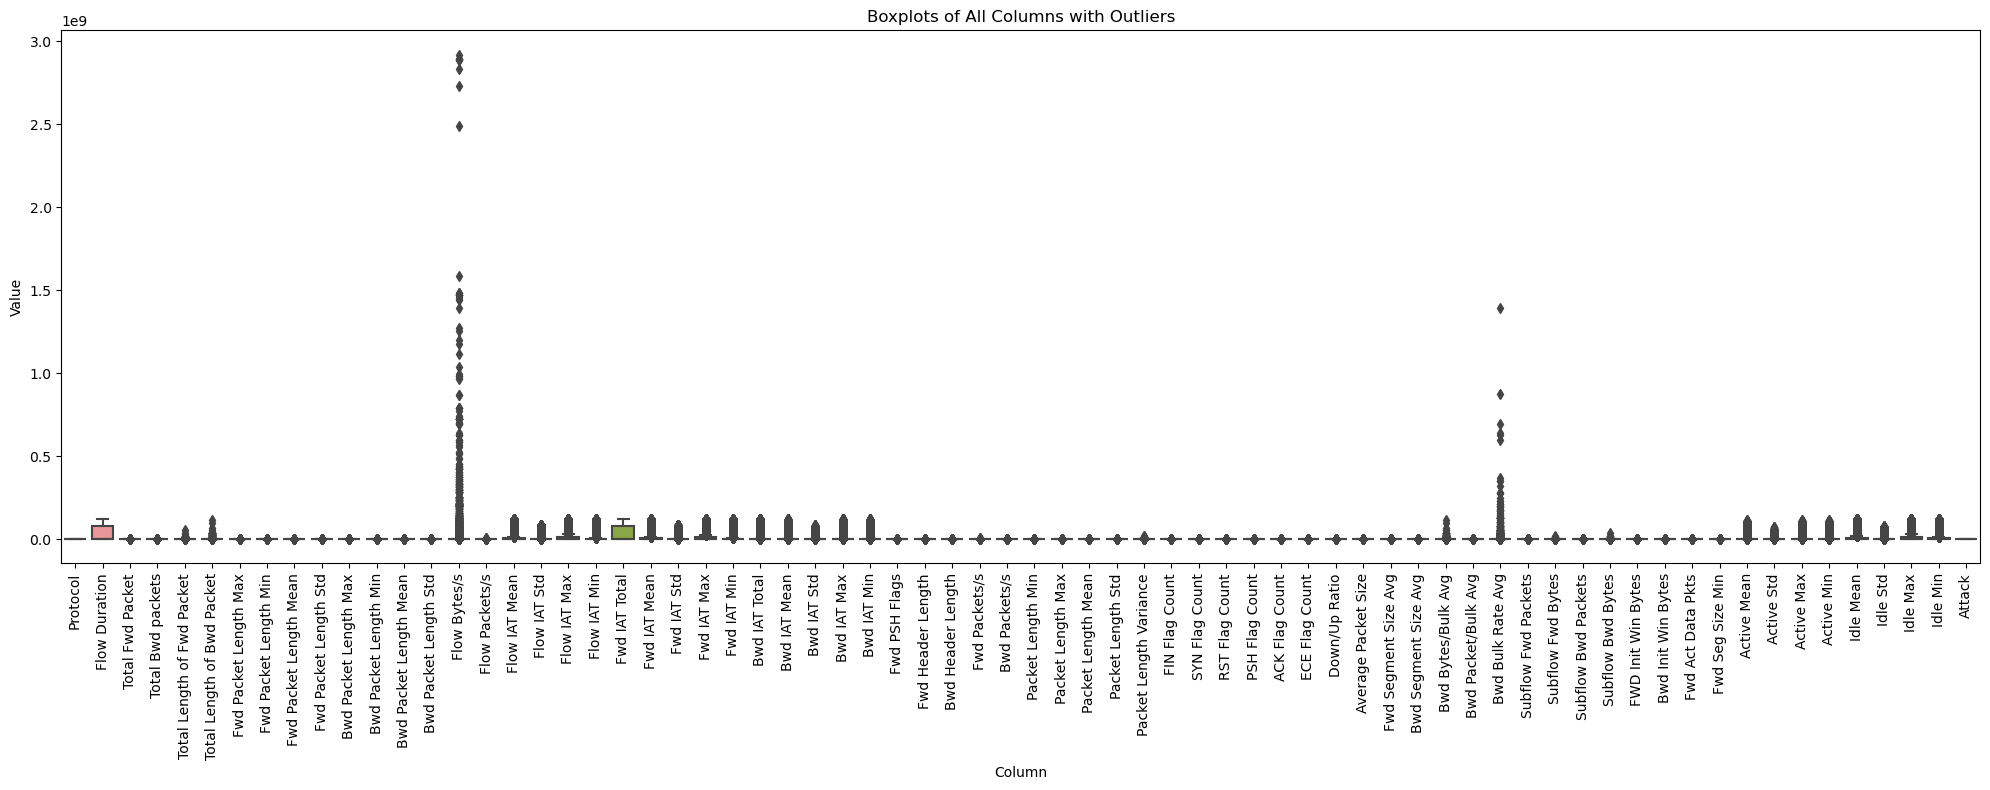

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

In [45]:
outliers_per_column = {}
for col in df2.select_dtypes(include=np.number).columns:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    outliers_per_column[col] = len(outliers)

In [46]:
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 0,
 'Total Fwd Packet': 260322,
 'Total Bwd packets': 153470,
 'Total Length of Fwd Packet': 316514,
 'Total Length of Bwd Packet': 306249,
 'Fwd Packet Length Max': 281495,
 'Fwd Packet Length Min': 294062,
 'Fwd Packet Length Mean': 256900,
 'Fwd Packet Length Std': 399623,
 'Bwd Packet Length Max': 297008,
 'Bwd Packet Length Min': 180297,
 'Bwd Packet Length Mean': 213554,
 'Bwd Packet Length Std': 280113,
 'Flow Bytes/s': 269173,
 'Flow Packets/s': 194913,
 'Flow IAT Mean': 232054,
 'Flow IAT Std': 273983,
 'Flow IAT Max': 315334,
 'Flow IAT Min': 193157,
 'Fwd IAT Total': 0,
 'Fwd IAT Mean': 283450,
 'Fwd IAT Std': 256991,
 'Fwd IAT Max': 315519,
 'Fwd IAT Min': 229249,
 'Bwd IAT Total': 455955,
 'Bwd IAT Mean': 455981,
 'Bwd IAT Std': 380258,
 'Bwd IAT Max': 455983,
 'Bwd IAT Min': 374576,
 'Fwd PSH Flags': 95782,
 'Fwd Header Length': 219957,
 'Bwd Header Length': 292504,
 'Fwd Packets/s': 189889,
 'Bwd Packets/s': 180709,
 'Packet Length Min':

In [47]:
outliers_per_column.pop("Attack")
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 0,
 'Total Fwd Packet': 260322,
 'Total Bwd packets': 153470,
 'Total Length of Fwd Packet': 316514,
 'Total Length of Bwd Packet': 306249,
 'Fwd Packet Length Max': 281495,
 'Fwd Packet Length Min': 294062,
 'Fwd Packet Length Mean': 256900,
 'Fwd Packet Length Std': 399623,
 'Bwd Packet Length Max': 297008,
 'Bwd Packet Length Min': 180297,
 'Bwd Packet Length Mean': 213554,
 'Bwd Packet Length Std': 280113,
 'Flow Bytes/s': 269173,
 'Flow Packets/s': 194913,
 'Flow IAT Mean': 232054,
 'Flow IAT Std': 273983,
 'Flow IAT Max': 315334,
 'Flow IAT Min': 193157,
 'Fwd IAT Total': 0,
 'Fwd IAT Mean': 283450,
 'Fwd IAT Std': 256991,
 'Fwd IAT Max': 315519,
 'Fwd IAT Min': 229249,
 'Bwd IAT Total': 455955,
 'Bwd IAT Mean': 455981,
 'Bwd IAT Std': 380258,
 'Bwd IAT Max': 455983,
 'Bwd IAT Min': 374576,
 'Fwd PSH Flags': 95782,
 'Fwd Header Length': 219957,
 'Bwd Header Length': 292504,
 'Fwd Packets/s': 189889,
 'Bwd Packets/s': 180709,
 'Packet Length Min':

In [48]:
#Cap Outliers (Winsorize / Clipping Approach)
def cap_outliers_iqr(df2, column):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df2[column] = np.where(df2[column] < lower, lower,
                 np.where(df2[column] > upper, upper, df2[column]))
    return df2

# Apply to columns with outliers
for col, count in outliers_per_column.items():
    if count > 0:
        df2 = cap_outliers_iqr(df2, col)

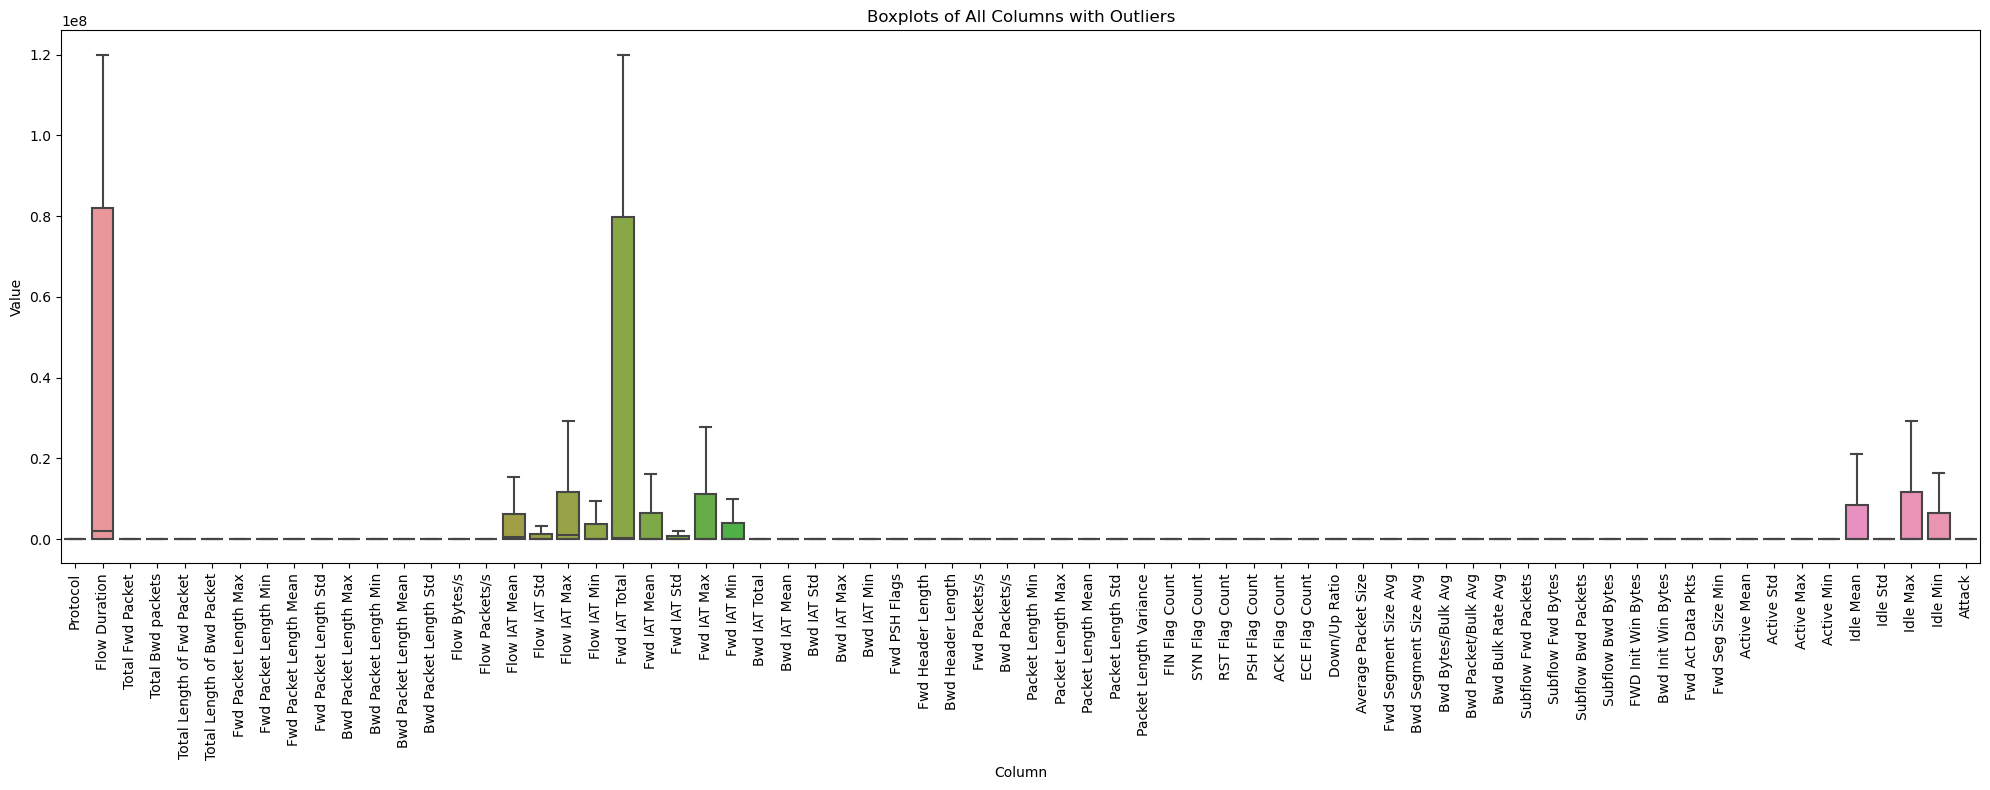

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

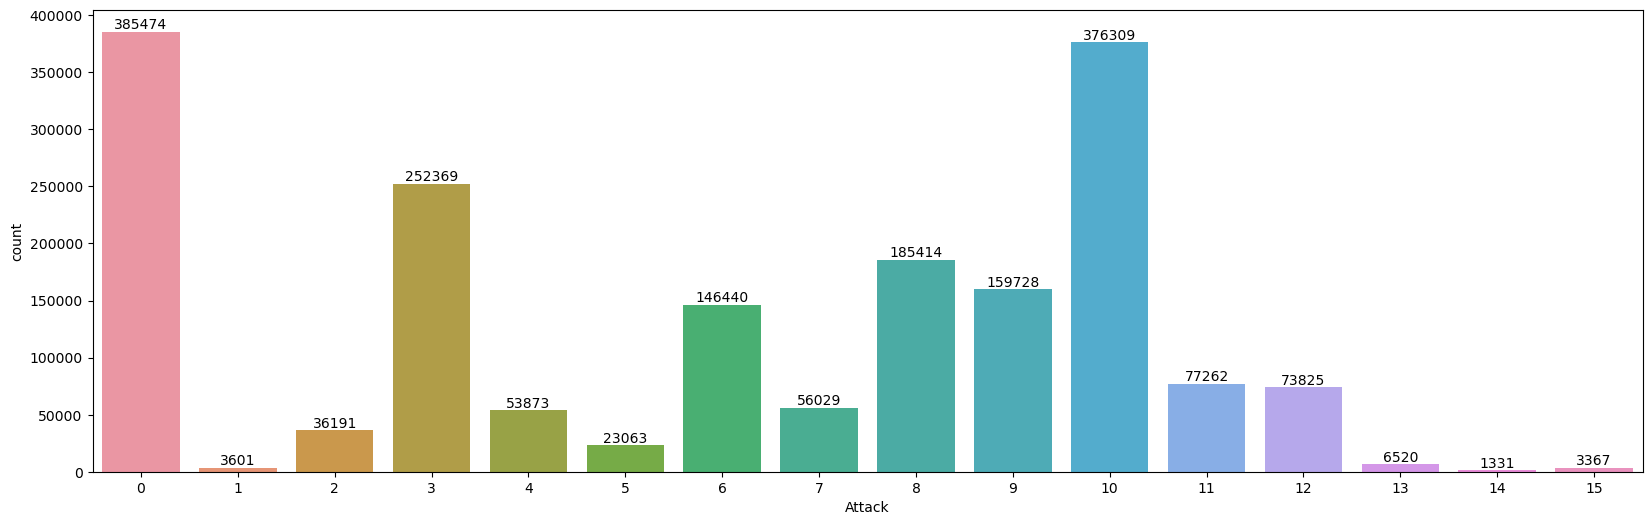

In [50]:
plt.figure(figsize=(20,6))
ax = sns.countplot(x='Attack',data=df2)
for i in ax.containers:
    ax.bar_label(i,)

In [51]:
df2.shape

(1840796, 70)

In [52]:
df2.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
      

In [53]:
columns = ['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
       'Bwd Bytes/Bulk Avg', 'Bwd Packet/Bulk Avg', 'Bwd Bulk Rate Avg', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Act Data Pkts', 'Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']

In [29]:
!pip install --upgrade scikit-learn
!pip install --upgrade imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB 217.9 kB/s eta 0:00:41
   ---------------------------------------- 0.1/8.9 MB 656.4 kB/s eta 0:00:14
   - -------------------------------------- 0.2/8.9 MB 1.5 MB/s eta 0:00:06
   - -------------------------------------- 0.4/8.9 MB 2.0 MB/s eta 0:00:05
   --- ------------------------------------ 0.7/8.9 MB 3.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/8.9 MB 4.6 MB/s eta 0:00:02
   -------- ------------------------------- 1.8/8.9 MB 5.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.4/8.9 MB 5.2 MB/s eta 0:00:02
   -------------- --

  You can safely remove it manually.


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/240.0 kB ? eta -:--:--
   - -------------------------------------- 10.2/240.0 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/240.0 kB 262.6 kB/s eta 0:00:01
   --------- ----------------------------- 61.4/240.0 kB 465.5 kB/s eta 0:00:01
   ---------------------------------- ----- 204.8/240.0 kB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 240.0/240.0 kB 1.2 MB/s eta 0:00:00


In [54]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split features/labels
X = df2.drop(columns=['Attack'])
y = df2['Attack']

# Train-test split first (important to avoid leakage!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Apply SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_bal.value_counts())

Attack
0     308379
10    301047
3     201895
8     148331
9     127782
6     117152
11     61810
12     59060
7      44823
4      43098
2      28953
5      18450
13      5216
1       2881
15      2694
14      1065
Name: count, dtype: int64
Attack
12    308379
4     308379
0     308379
9     308379
10    308379
3     308379
8     308379
11    308379
6     308379
7     308379
5     308379
2     308379
14    308379
15    308379
13    308379
1     308379
Name: count, dtype: int64


<h2>ML Models</h2>

In [31]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [33]:
pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [34]:
pip install catboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



🔹 Training Logistic Regression...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic Regression Performance:
  Accuracy:  0.6412
  Precision: 0.6173
  Recall:    0.6412
  F1-score:  0.6104


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize


Classification Report:
               precision    recall  f1-score   support

           0       0.45      0.67      0.53     77095
           1       0.00      0.00      0.00       720
           2       0.00      0.00      0.00      7238
           3       0.98      0.95      0.96     50474
           4       0.71      0.61      0.65     10775
           5       0.16      0.00      0.00      4613
           6       0.93      0.92      0.93     29288
           7       0.62      0.76      0.69     11206
           8       0.98      0.96      0.97     37083
           9       0.44      0.25      0.32     31946
          10       0.52      0.65      0.58     75262
          11       0.22      0.01      0.01     15452
          12       0.50      0.11      0.18     14765
          13       0.00      0.00      0.00      1304
          14       0.00      0.00      0.00       266
          15       0.00      0.00      0.00       673

    accuracy                           0.64    368160
 

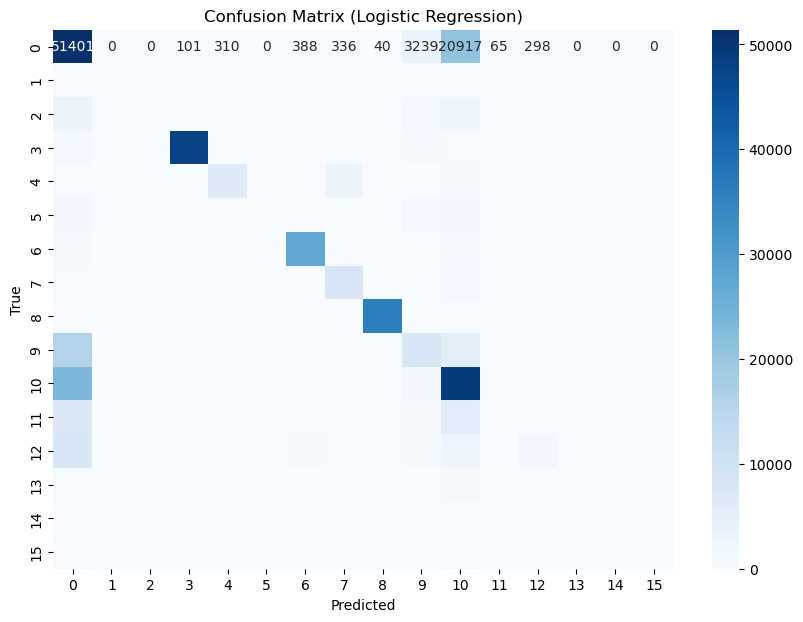


🔹 Training Random Forest...
Random Forest Performance:
  Accuracy:  0.7637
  Precision: 0.7596
  Recall:    0.7637
  F1-score:  0.7606

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.73      0.70     77095
           1       0.16      0.13      0.14       720
           2       0.32      0.20      0.24      7238
           3       0.98      0.96      0.97     50474
           4       0.86      0.86      0.86     10775
           5       0.29      0.18      0.22      4613
           6       0.96      0.93      0.95     29288
           7       0.82      0.80      0.81     11206
           8       1.00      0.99      0.99     37083
           9       0.64      0.71      0.67     31946
          10       0.71      0.72      0.72     75262
          11       0.57      0.52      0.55     15452
          12       0.52      0.45      0.48     14765
          13       0.30      0.22      0.25      1304
          14       0.41     

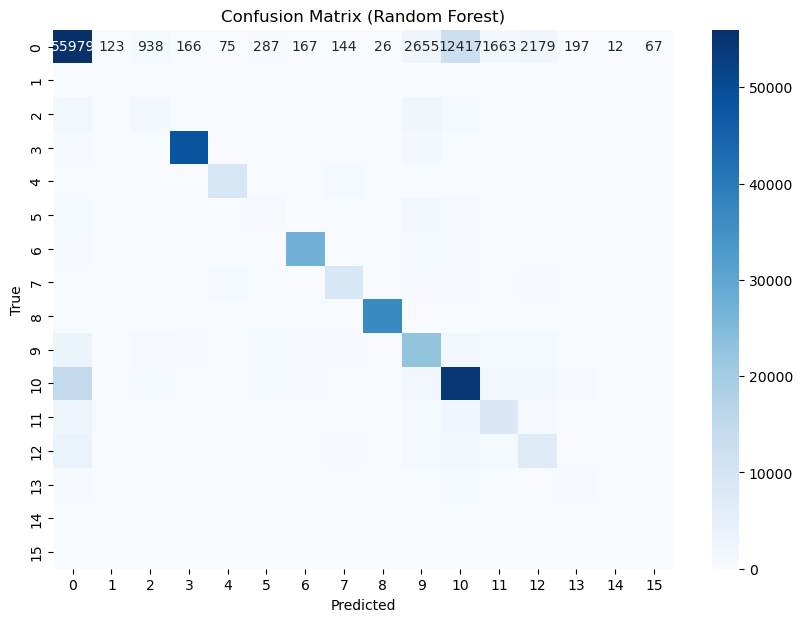


🔹 Training XGBoost...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [17:33:38] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Performance:
  Accuracy:  0.7786
  Precision: 0.7939
  Recall:    0.7786
  F1-score:  0.7657

Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.88      0.72     77095
           1       0.52      0.07      0.12       720
           2       0.76      0.09      0.16      7238
           3       1.00      0.95      0.98     50474
           4       0.89      0.88      0.89     10775
           5       0.59      0.08      0.15      4613
           6       0.99      0.93      0.96     29288
           7       0.81      0.88      0.84     11206
           8       1.00      0.99      0.99     37083
           9       0.64      0.72      0.68     31946
          10       0.77      0.69      0.73     75262
          11       0.67      0.42      0.51     15452
          12       0.78      0.30      0.43     14765
          13       0.63      0.15      0.25      1304
          14       0.93      0.24      0.38       266
         

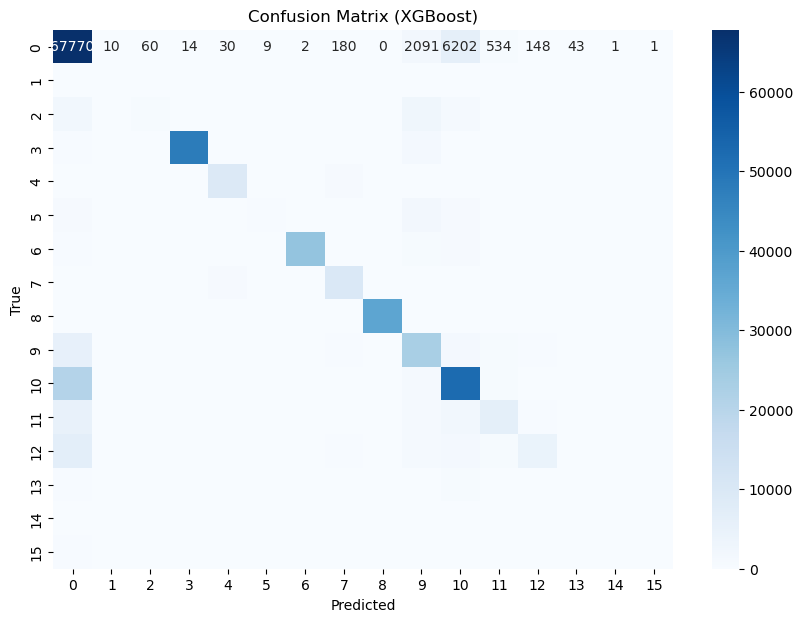


🔹 Training KNN...
KNN Performance:
  Accuracy:  0.7612
  Precision: 0.7603
  Recall:    0.7612
  F1-score:  0.7543

Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.79      0.69     77095
           1       0.27      0.13      0.17       720
           2       0.41      0.17      0.24      7238
           3       0.99      0.95      0.97     50474
           4       0.86      0.87      0.87     10775
           5       0.31      0.12      0.17      4613
           6       0.98      0.93      0.96     29288
           7       0.82      0.83      0.83     11206
           8       1.00      0.99      0.99     37083
           9       0.66      0.70      0.68     31946
          10       0.70      0.68      0.69     75262
          11       0.61      0.49      0.54     15452
          12       0.64      0.37      0.47     14765
          13       0.42      0.15      0.22      1304
          14       0.75      0.25      0.38     

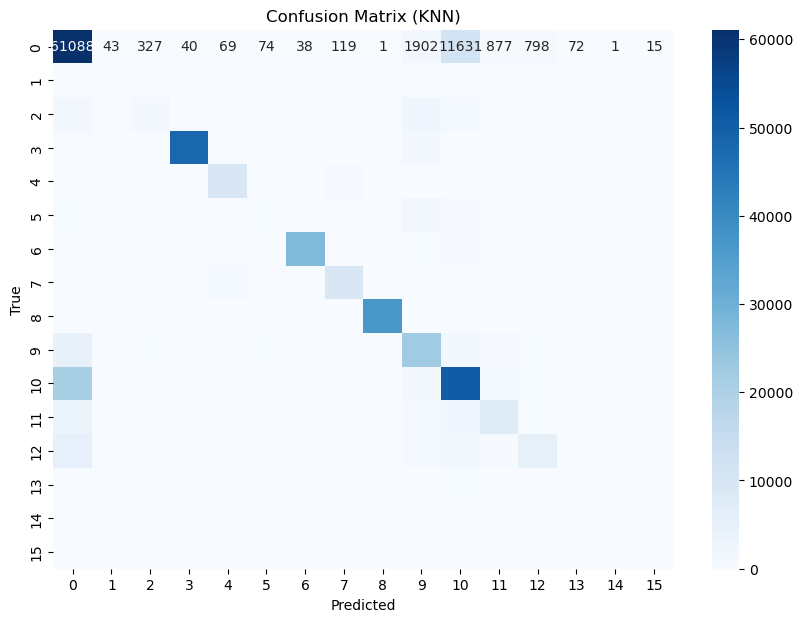


🔹 Training Naive Bayes...
Naive Bayes Performance:
  Accuracy:  0.3788
  Precision: 0.5125
  Recall:    0.3788
  F1-score:  0.3854

Classification Report:
               precision    recall  f1-score   support

           0       0.35      0.12      0.18     77095
           1       0.00      0.56      0.01       720
           2       0.06      0.13      0.09      7238
           3       0.96      0.83      0.89     50474
           4       0.40      0.37      0.39     10775
           5       0.00      0.00      0.00      4613
           6       0.57      0.84      0.68     29288
           7       0.18      0.78      0.29     11206
           8       0.92      0.98      0.95     37083
           9       0.46      0.10      0.17     31946
          10       0.52      0.10      0.17     75262
          11       0.04      0.02      0.03     15452
          12       0.08      0.16      0.11     14765
          13       0.05      0.06      0.05      1304
          14       0.00      0.0

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

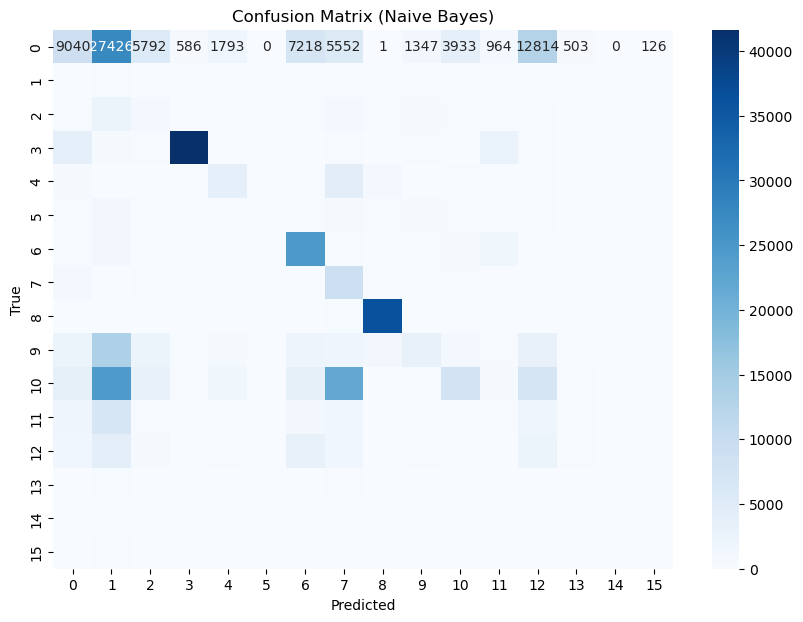


🔹 Training Decision Tree...
Decision Tree Performance:
  Accuracy:  0.6991
  Precision: 0.7238
  Recall:    0.6991
  F1-score:  0.6805

Classification Report:
               precision    recall  f1-score   support

           0       0.47      0.85      0.61     77095
           1       0.93      0.02      0.04       720
           2       0.38      0.01      0.01      7238
           3       1.00      0.95      0.98     50474
           4       0.88      0.77      0.82     10775
           5       0.34      0.01      0.01      4613
           6       0.99      0.92      0.95     29288
           7       0.86      0.75      0.80     11206
           8       1.00      0.96      0.98     37083
           9       0.62      0.42      0.50     31946
          10       0.67      0.60      0.63     75262
          11       0.53      0.22      0.31     15452
          12       0.76      0.16      0.27     14765
          13       0.00      0.00      0.00      1304
          14       0.00     

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

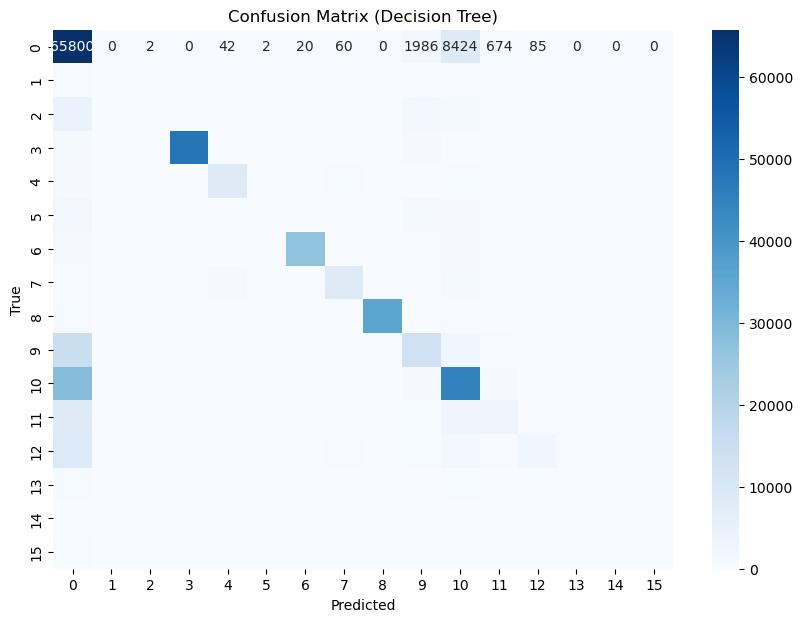


🔹 Training AdaBoost...
AdaBoost Performance:
  Accuracy:  0.5292
  Precision: 0.4101
  Recall:    0.5292
  F1-score:  0.4583

Classification Report:
               precision    recall  f1-score   support

           0       0.37      0.66      0.47     77095
           1       0.00      0.00      0.00       720
           2       0.00      0.00      0.00      7238
           3       0.87      0.95      0.91     50474
           4       0.00      0.00      0.00     10775
           5       0.00      0.00      0.00      4613
           6       0.66      0.84      0.74     29288
           7       0.00      0.00      0.00     11206
           8       0.81      0.90      0.85     37083
           9       0.00      0.00      0.00     31946
          10       0.40      0.50      0.44     75262
          11       0.00      0.00      0.00     15452
          12       0.00      0.00      0.00     14765
          13       0.00      0.00      0.00      1304
          14       0.00      0.00     

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

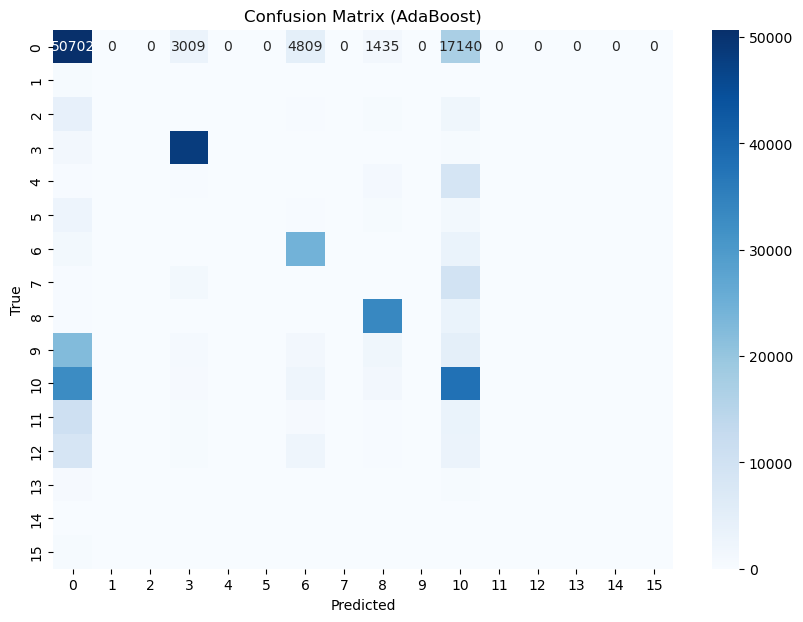


🔹 Training Extra Trees...
Extra Trees Performance:
  Accuracy:  0.7547
  Precision: 0.7511
  Recall:    0.7547
  F1-score:  0.7522

Classification Report:
               precision    recall  f1-score   support

           0       0.66      0.71      0.68     77095
           1       0.16      0.14      0.15       720
           2       0.29      0.20      0.23      7238
           3       0.97      0.96      0.97     50474
           4       0.86      0.86      0.86     10775
           5       0.26      0.18      0.21      4613
           6       0.96      0.93      0.94     29288
           7       0.81      0.79      0.80     11206
           8       0.99      0.99      0.99     37083
           9       0.64      0.69      0.66     31946
          10       0.70      0.71      0.70     75262
          11       0.56      0.52      0.54     15452
          12       0.51      0.45      0.48     14765
          13       0.27      0.21      0.23      1304
          14       0.36      0.2

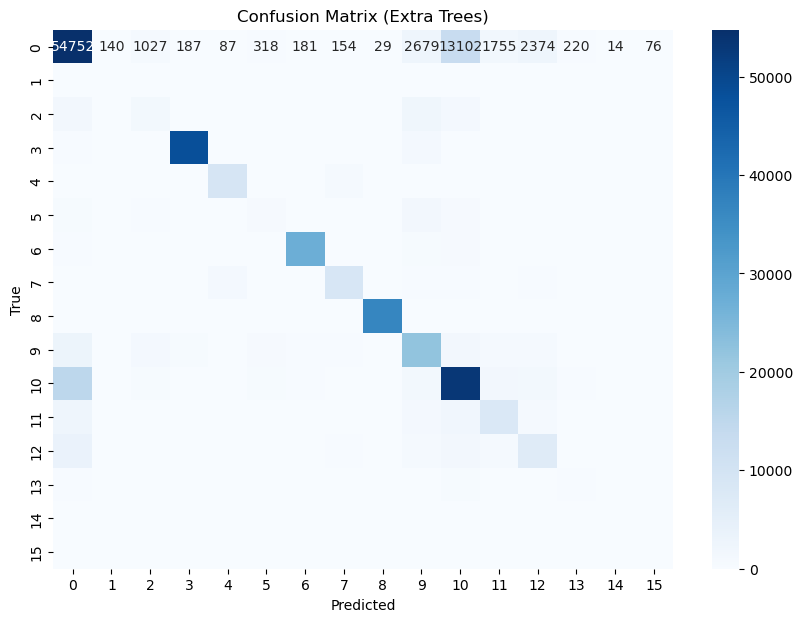


🔹 Training LightGBM...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Performance:
  Accuracy:  0.7608
  Precision: 0.7693
  Recall:    0.7608
  F1-score:  0.7485

Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.86      0.70     77095
           1       0.17      0.09      0.12       720
           2       0.58      0.09      0.15      7238
           3       0.99      0.95      0.97     50474
           4       0.87      0.86      0.86     10775
           5       0.38      0.08      0.13      4613
           6       0.99      0.92      0.95     29288
           7       0.79      0.87      0.83     11206
           8       0.98      0.99      0.98     37083
           9       0.62      0.67      0.64     31946
          10       0.76      0.67      0.71     75262
          11       0.64      0.38      0.48     15452
          12       0.74      0.27      0.40     14765
          13       0.33      0.17      0.23      1304
          14       0.25      0.22      0.23       266
        

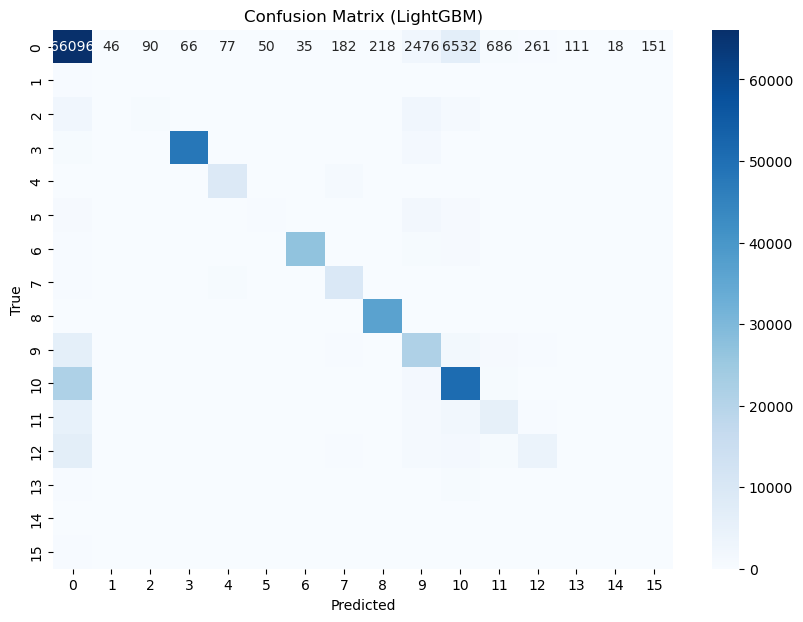


🔹 Training CatBoost...
CatBoost Performance:
  Accuracy:  0.7501
  Precision: 0.7728
  Recall:    0.7501
  F1-score:  0.7318

Classification Report:
               precision    recall  f1-score   support

           0       0.56      0.86      0.68     77095
           1       1.00      0.02      0.04       720
           2       0.86      0.04      0.08      7238
           3       0.99      0.95      0.97     50474
           4       0.84      0.86      0.85     10775
           5       0.48      0.02      0.04      4613
           6       0.99      0.92      0.95     29288
           7       0.80      0.81      0.81     11206
           8       1.00      0.99      0.99     37083
           9       0.60      0.66      0.63     31946
          10       0.73      0.67      0.70     75262
          11       0.68      0.29      0.40     15452
          12       0.76      0.21      0.33     14765
          13       0.92      0.03      0.05      1304
          14       1.00      0.20     

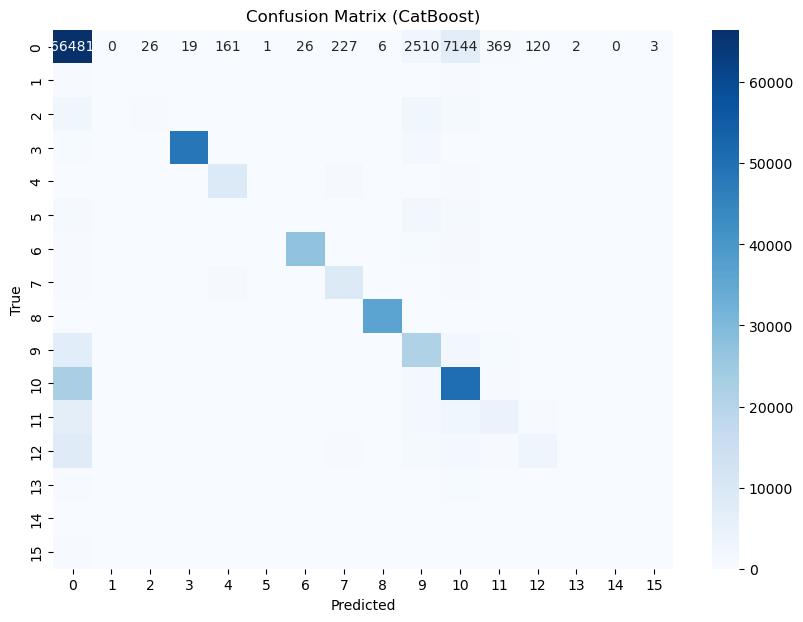


📊 Final Comparison:
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.641197   0.617297  0.641197  0.610367
Random Forest        0.763741   0.759602  0.763741  0.760587
XGBoost              0.778602   0.793891  0.778602  0.765711
KNN                  0.761153   0.760318  0.761153  0.754285
Naive Bayes          0.378824   0.512491  0.378824  0.385438
Decision Tree        0.699144   0.723769  0.699144  0.680534
AdaBoost             0.529221   0.410076  0.529221  0.458308
Extra Trees          0.754685   0.751134  0.754685  0.752204
LightGBM             0.760764   0.769344  0.760764  0.748480
CatBoost             0.750109   0.772812  0.750109  0.731813


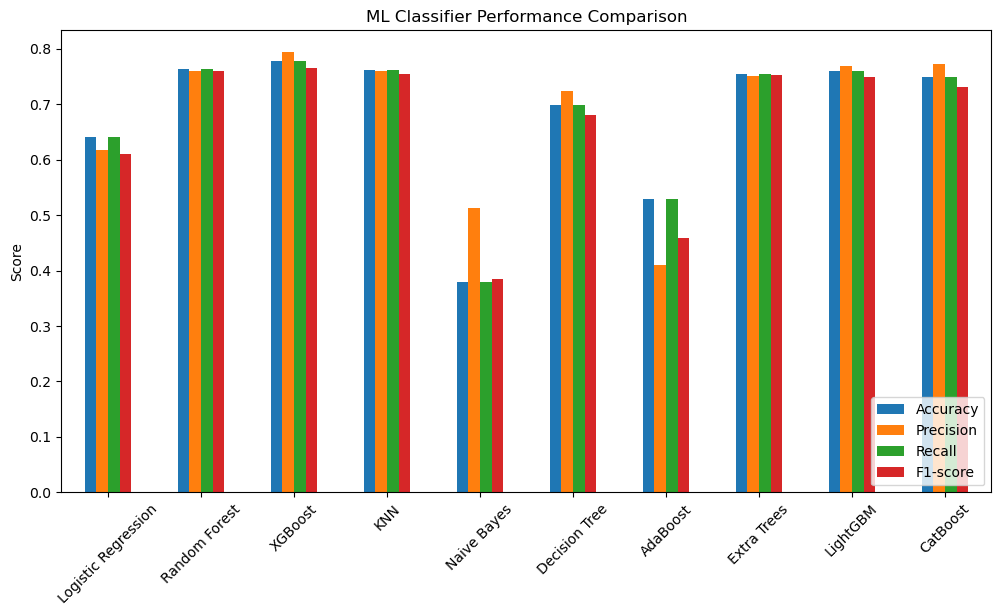

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature scaling (important for SVM, KNN, LR)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================
# Define Models
# =====================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}

# =====================================
# Train & Evaluate
# =====================================
for name, model in models.items():
    print(f"\n🔹 Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

    print(f"{name} Performance:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=encoder.classes_.astype(str)))

    # Confusion Matrix
    class_names = encoder.classes_

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f"Confusion Matrix ({name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(f"ML-Multi-Attack/Multiclass-ml-{name}.pdf")   # <-- save as PDF
    plt.show()


# =====================================
# Compare Results
# =====================================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison:\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack/Multi-ml-compare.pdf")   # <-- save as PDF
plt.show()


<h3>with k5-fold cross validation</h3>


🔹 Training Logistic Regression with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\

Logistic Regression Avg Performance:
  Accuracy:  0.6415
  Precision: 0.6179
  Recall:    0.6415
  F1-score:  0.6106

🔹 Training Random Forest with 5-Fold Cross Validation...
Random Forest Avg Performance:
  Accuracy:  0.7637
  Precision: 0.7594
  Recall:    0.7637
  F1-score:  0.7605

🔹 Training XGBoost with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [22:40:04] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [22:45:44] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [22:51:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [22:57:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:7

XGBoost Avg Performance:
  Accuracy:  0.7790
  Precision: 0.7946
  Recall:    0.7790
  F1-score:  0.7663

🔹 Training KNN with 5-Fold Cross Validation...
KNN Avg Performance:
  Accuracy:  0.7616
  Precision: 0.7605
  Recall:    0.7616
  F1-score:  0.7546

🔹 Training Naive Bayes with 5-Fold Cross Validation...
Naive Bayes Avg Performance:
  Accuracy:  0.3794
  Precision: 0.5122
  Recall:    0.3794
  F1-score:  0.3861

🔹 Training Decision Tree with 5-Fold Cross Validation...
Decision Tree Avg Performance:
  Accuracy:  0.6985
  Precision: 0.7223
  Recall:    0.6985
  F1-score:  0.6806

🔹 Training AdaBoost with 5-Fold Cross Validation...
AdaBoost Avg Performance:
  Accuracy:  0.5240
  Precision: 0.4072
  Recall:    0.5240
  F1-score:  0.4532

🔹 Training Extra Trees with 5-Fold Cross Validation...
Extra Trees Avg Performance:
  Accuracy:  0.7546
  Precision: 0.7508
  Recall:    0.7546
  F1-score:  0.7520

🔹 Training LightGBM with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

LightGBM Avg Performance:
  Accuracy:  0.7631
  Precision: 0.7691
  Recall:    0.7631
  F1-score:  0.7519

🔹 Training CatBoost with 5-Fold Cross Validation...
CatBoost Avg Performance:
  Accuracy:  0.7498
  Precision: 0.7747
  Recall:    0.7498
  F1-score:  0.7313

📊 Final Comparison (5-Fold CV):
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.641530   0.617926  0.641530  0.610648
Random Forest        0.763713   0.759399  0.763713  0.760471
XGBoost              0.779011   0.794568  0.779011  0.766306
KNN                  0.761607   0.760493  0.761607  0.754558
Naive Bayes          0.379440   0.512193  0.379440  0.386129
Decision Tree        0.698487   0.722331  0.698487  0.680604
AdaBoost             0.524033   0.407198  0.524033  0.453241
Extra Trees          0.754595   0.750825  0.754595  0.751987
LightGBM             0.763070   0.769135  0.763070  0.751947
CatBoost             0.749803   0.774651  0.749803  0.731290


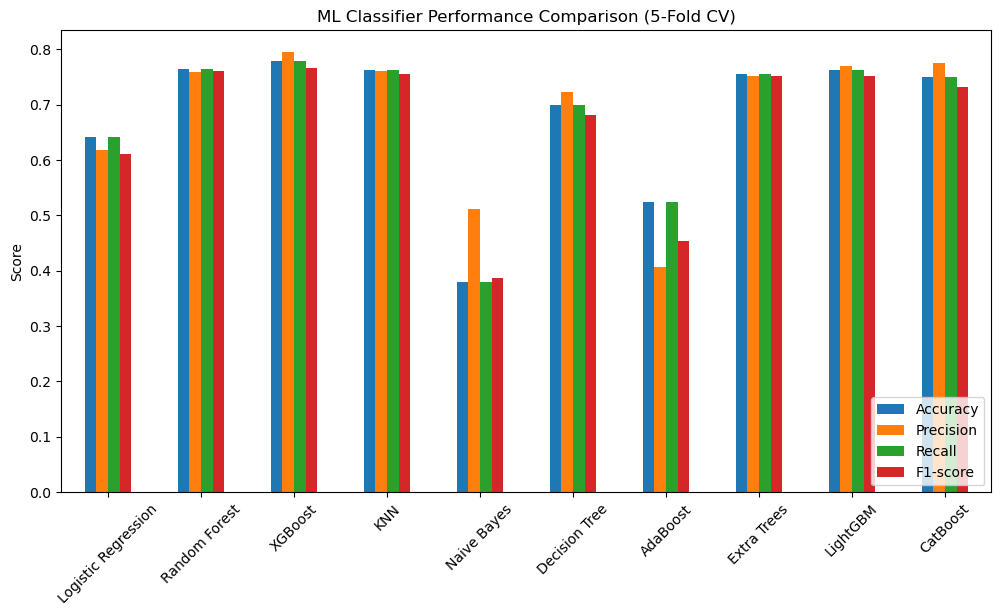

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# =============================
# Encode labels
# =============================
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# =============================
# Define Models
# =============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =============================
# Train & Cross-Validate
# =============================
for name, model in models.items():
    print(f"\n🔹 Training {name} with 5-Fold Cross Validation...")

    acc_scores, prec_scores, rec_scores, f1_scores = [], [], [], []

    fold = 1
    for train_idx, test_idx in kf.split(X, y_encoded):
        # Use iloc to index rows correctly
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

        # Feature scaling
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # Train & predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)


        # Metrics
        acc_scores.append(accuracy_score(y_test, y_pred))
        prec_scores.append(precision_score(y_test, y_pred, average="weighted", zero_division=0))
        rec_scores.append(recall_score(y_test, y_pred, average="weighted", zero_division=0))
        f1_scores.append(f1_score(y_test, y_pred, average="weighted", zero_division=0))

        # Save one confusion matrix per fold (optional)
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=encoder.classes_,
                    yticklabels=encoder.classes_)
        plt.title(f"{name} - Confusion Matrix (Fold {fold})")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(f"ML-Multi-Attack/Multi-ml-{name}-fold{fold}.pdf")
        plt.close()
        fold += 1

    # Average results
    results[name] = {
        "Accuracy": np.mean(acc_scores),
        "Precision": np.mean(prec_scores),
        "Recall": np.mean(rec_scores),
        "F1-score": np.mean(f1_scores)
    }

    print(f"{name} Avg Performance:")
    print(f"  Accuracy:  {np.mean(acc_scores):.4f}")
    print(f"  Precision: {np.mean(prec_scores):.4f}")
    print(f"  Recall:    {np.mean(rec_scores):.4f}")
    print(f"  F1-score:  {np.mean(f1_scores):.4f}")

# =============================
# Compare Results
# =============================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison (5-Fold CV):\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison (5-Fold CV)")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack/Multi-ml-compare-5fold.pdf")
plt.show()
